# Hệ thống Phân tích Cảm xúc TikTok Song ngữ (Tiếng Việt & Tiếng Anh)

- **Dữ liệu thu thập (`data/<post_id>/`):** Tự động tải video (`video.mp4`), `metadata.json` và bình luận thô (`raw_comments.csv`).
- **Giai đoạn 1 — AI Đầu vào (`gemma4-e2b-opt`):** Đọc khung hình + lời thoại Whisper (tự nhận diện VI/EN) + caption để trích xuất 8 trường ngữ cảnh bài đăng.
- **Giai đoạn 2 — Tiền xử lý & Lọc nhiễu (`src/preprocessing/text_cleaner.py`):** Nhận diện ngôn ngữ (`vi` / `en`), lọc bình luận nhiễu (`@tag` bạn bè, tên riêng đơn lẻ qua `underthesea`, URL, seeding, spam quảng cáo, ngôn ngữ khác `FILTERED_UNSUPPORTED_LANG`).
- **Giai đoạn 3 — Lõi ML & Deep Learning (`src/models/classical_ml.py` + `sentiment_engine.py`):**
  - **Tiếng Việt:** `TF-IDF (NB/LR/SVM)` + `Vietnamese Lexicon` + `ViSoBERT` + `PhoBERT` + `PhoBERT Emotion (7 cung bậc)`.
  - **Tiếng Anh:** `TF-IDF (NB/LR/SVM)` + `English Lexicon` + `Twitter-RoBERTa` + `DistilRoBERTa Emotion (7 cung bậc)`.
  - **Thang điểm kép nhất quán:** `polarity_score` (`-1.0..+1.0`), `score_5` (`1..5`), `score_10` (`0..10`).
- **Giai đoạn 4 — AI Đầu ra (`src/models/gemma_auditor.py`):** `gemma4-e2b-opt` thẩm định thực tế **100% bình luận hợp lệ**, phát hiện nói mỉa (`sarcasm`) và xuất kết quả cuối cùng ra **`outputs/<post_id>/`**.

> Đảm bảo container Ollama `gemma4-e2b` đang chạy (`docker compose up -d` trong `AI_Local/gemma4-e2b`) trước khi chạy.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src.pipeline import SentimentPipeline
from src.visualization import plot_sentiment_dashboard

# === NHẬP LINK VIDEO TIKTOK ===
TIKTOK_URL = input("Nhập link video TikTok: ").strip()

# Cấu hình hệ thống
ENABLE_AUDIO = True
RUN_AI_AUDIT = True          # Gemma 4 E2B thẩm định thực tế ở đầu ra
AUDIT_LIMIT = None           # None = chấm 100% bình luận hợp lệ
MAX_COMMENTS = 200
DEDUPLICATE_STATS = False    # True nếu muốn loại bỏ bình luận copy-paste khỏi tỷ lệ %
DATA_DIR = Path("data")      # Nơi lưu toàn bộ dữ liệu thu thập thô
OUTPUT_DIR = Path("outputs") # Nơi xuất kết quả cuối cùng sau xử lý

In [2]:
# === CHẠY TOÀN BỘ PIPELINE 4 GIAI ĐOẠN ===
if not TIKTOK_URL:
    raise ValueError("Vui lòng nhập link video TikTok vào biến TIKTOK_URL.")

pipeline = SentimentPipeline()
report = pipeline.run(
    tiktok_url=TIKTOK_URL,
    enable_audio=ENABLE_AUDIO,
    run_ai_audit=RUN_AI_AUDIT,
    audit_limit=AUDIT_LIMIT,
    max_comments=MAX_COMMENTS,
    deduplicate_stats=DEDUPLICATE_STATS,
    data_dir=DATA_DIR,
    output_dir=OUTPUT_DIR,
)

run_name = report["run_name"]
print(f"-> Dữ liệu thu thập lưu tại: {DATA_DIR / run_name}")
print(f"-> Kết quả xử lý xuất tại  : {OUTPUT_DIR / run_name}")

if report.get("media_analysis"):
    print("\n=== GIAI ĐOẠN 1: NGỮ CẢNH VIDEO (GEMMA 4 E2B) ===")
    print(json.dumps(report["media_analysis"], ensure_ascii=False, indent=2))

[Bước 0] Đang tải video & metadata vào data\7697460875690626322...
[Bước 0] Đang thu thập bình luận vào data\7697460875690626322\raw_comments.csv...
Đang mở trình duyệt tới: https://www.tiktok.com/@_kushiro1503_07/video/7697460875690626322?is_from_webapp=1&sender_device=pc

[Tạm dừng] Trên cửa sổ trình duyệt vừa mở:
  1. Đóng popup đăng nhập (hoặc đăng nhập nếu TikTok yêu cầu).
  2. Mở phần bình luận (nếu chưa hiện) hoặc hoàn tất xác minh (nếu có).
  Lần cuộn 1/40: thu được 37 bình luận
  Lần cuộn 2/40: thu được 50 bình luận
  Lần cuộn 3/40: thu được 67 bình luận
  Lần cuộn 4/40: thu được 78 bình luận
  Lần cuộn 5/40: thu được 82 bình luận
  Lần cuộn 6/40: thu được 99 bình luận
  Lần cuộn 7/40: thu được 100 bình luận
  Lần cuộn 8/40: thu được 100 bình luận
  Lần cuộn 9/40: thu được 100 bình luận
  Lần cuộn 10/40: thu được 100 bình luận
  Lần cuộn 11/40: thu được 100 bình luận
Không tải thêm được bình luận mới sau 4 lần cuộn liên tiếp, dừng thu thập.
[Giai đoạn 1] Gemma 4 E2B đang phân 

Model phobert-emotion: 100%|██████████| 3/3 [00:04<00:00,  1.36s/batch]
Some weights of the model checkpoint at cardiffnlp/twitter-roberta-base-sentiment-latest were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Model emotion-english-distilroberta-base: 100%|██████████| 1/1 [00:00<00:00,  1.58batch/s]


[Giai đoạn 4] Gemma 4 E2B đang thẩm định thực tế bình luận theo ngữ cảnh...


Gemma 4 E2B thẩm định thực tế: 100%|██████████| 12/12 [02:25<00:00, 12.14s/batch]


-> Dữ liệu thu thập lưu tại: data\7697460875690626322
-> Kết quả xử lý xuất tại  : outputs\7697460875690626322

=== GIAI ĐOẠN 1: NGỮ CẢNH VIDEO (GEMMA 4 E2B) ===
{
  "media_type": "video",
  "source_paths": [
    "data\\7697460875690626322\\video.mp4"
  ],
  "num_frames_used": 10,
  "has_audio": true,
  "caption": "Goat Marvel - Iron Man #ironman #spiderman #marvel #fyp #viral",
  "transcript": "We have a chance to bring her back. To bring everyone back. And you're telling me that you won't leave this room? Oh look, take a look at who's sitting on there. Mr. Stark is beating me. I want you to get it, sir.",
  "chu_de_chinh": "Phim Marvel/Iron Man",
  "muc_dich_chinh": "Giải trí",
  "quan_diem_noi_dung": "Chia sẻ khoảnh khắc hoặc nội dung hấp dẫn từ bộ phim/series Marvel, tập trung vào nhân vật Iron Man.",
  "doi_tuong_chinh": [
    "Iron Man",
    "Marvel",
    "Goat Marvel"
  ],
  "sac_thai_noi_dung": "Tích cực",
  "tom_tat_ngan": "Video là một đoạn cắt từ phim Marvel, có tiêu đề",
  

In [3]:
# === XEM KẾT QUẢ TÁCH BIỆT COMMENT SẠCH & COMMENT NHIỄU ===
print("=== THỐNG KÊ LỌC NHIỄU & NGÔN NGỮ ===")
print(json.dumps(report["noise_filter_summary"], ensure_ascii=False, indent=2))
if report.get("sentiment_summary"):
    print("Phân bố ngôn ngữ hợp lệ:", report["sentiment_summary"]["language_counts"])

exported = report.get("exported_files", {})
if "cleaned_final_results_csv" in exported:
    df_summary = pd.read_csv(exported["cleaned_final_results_csv"], encoding="utf-8-sig")
    print(f"\nBảng tóm gọn các cột chính (cleaned_final_results.csv): {len(df_summary)} dòng")
    display(df_summary.head(20))

if "final_results_csv" in exported:
    df_clean = pd.read_csv(exported["final_results_csv"], encoding="utf-8-sig")
    df_clean.columns = [c.split("\n", 1)[0] for c in df_clean.columns]
    print(f"\nSố comment sạch đầy đủ 42 cột (final_results.csv): {len(df_clean)}")
    display(df_clean[[
        "language", "original_text", "polarity_label", "polarity_score", "score_5", "score_10",
        "emotion_vi", "pred_nb", "pred_lr", "pred_svm", "pred_dl_primary",
        "gemma_polarity", "gemma_emotion_vi", "gemma_score_5", "gemma_is_sarcasm", "gemma_reason"
    ]].head(20))

if "filtered_noise_csv" in exported:
    df_noise = pd.read_csv(exported["filtered_noise_csv"], encoding="utf-8-sig")
    print(f"\nSố comment bị lọc nhiễu (filtered_noise.csv): {len(df_noise)}")
    display(df_noise.head(20))

=== THỐNG KÊ LỌC NHIỄU & NGÔN NGỮ ===
{
  "total_raw_comments": 100,
  "valid_comments": 94,
  "filtered_noise_count": 6,
  "duplicate_valid_count": 0,
  "filter_reasons": {
    "FILTERED_TAG_FRIEND": 2,
    "FILTERED_URL_OR_SYMBOL": 4
  }
}
Phân bố ngôn ngữ hợp lệ: {'vi': 83, 'en': 11}

Bảng tóm gọn các cột chính (cleaned_final_results.csv): 94 dòng


,username\n(tên tài khoản),likes\n(lượt thích),created_at\n(thời gian đăng),language\n(ngôn ngữ),original_text\n(nội dung gốc),polarity_vi\n(cực tính hệ thống),score_5\n(điểm thang 1-5),score_10\n(điểm thang 0-10),emotion_vi\n(cảm xúc 7 cung bậc),polarity_confidence\n(độ tự tin cực tính),gemma_polarity_vi\n(cực tính gemma tiếng việt),gemma_score_5\n(điểm 1-5 gemma),gemma_is_sarcasm\n(nói mỉa theo gemma),gemma_agrees_polarity\n(khớp cực tính với gemma),gemma_reason\n(lý do gemma giải thích)
0,_vladilenamilize_,1287,2026-10-17 12:14:58,vi,người sợ chết nhất nhưng luôn chọn hy sinh bản...,Tiêu cực,2,3.29,Lo lắng / Sợ hãi,0.4765,Tích cực,4,False,False,Bình luận thể hiện sự ngưỡng mộ đối với sự hy ...
1,playboiz36,418,2026-10-17 13:26:47,vi,giác quan nhện mới giúp nhện nói nhiều v đc chứ,Trung tính,3,5.95,Trung tính / Khác,0.5346,Trung tính,3,False,True,Đây là một câu hỏi mang tính chất suy đoán về ...
2,n..._am,334,2026-10-17 12:28:51,vi,Bắt đầu = Iron man\nKết thúc = Iron man\n🥹🥹🥹🥹🥹...,Tích cực,5,8.33,Vui vẻ / Hài lòng,0.7332,Tích cực,5,False,True,Bình luận thể hiện sự yêu thích và sự tập trun...
3,altron578,107,2026-10-18 12:38:34,vi,Sau khi trở về trái đất câu đầu tiên Tony nói ...,Tiêu cực,1,0.82,Buồn bã,0.8471,Tích cực,4,False,False,Bình luận thể hiện sự xúc động mạnh mẽ trước m...
4,leuleu.008,73,2026-10-17 13:09:26,vi,Cái thg báo starlord báo hại cả team còn,Tiêu cực,1,1.80,Lo lắng / Sợ hãi,0.7132,Tiêu cực,2,False,True,Bình luận thể hiện sự thất vọng hoặc không hài...
5,nizuilandebaobei,69,2026-10-17 13:38:07,vi,kiểu tại sao mọi người hay bảo tại star lord n...,Trung tính,3,4.95,Chán ghét / Khó chịu,0.4831,Trung tính,3,False,True,"Đây là một câu hỏi mang tính chất tìm hiểu, kh..."
6,emhung456_,44,2026-10-17 09:56:11,en,I love doom,Tích cực,5,8.92,Buồn bã,0.8468,Tích cực,4,False,True,Đây là lời bày tỏ sự yêu thích đối với một nhâ...
7,hai.hhh2323,16,2026-10-17 12:37:28,vi,Thor a làm gì vậy : tôi nhắm vào đầu🤣,Tiêu cực,2,3.78,Tức giận,0.4588,Trung tính,3,False,False,"Đây là một bình luận mang tính chất đùa vui, k..."
8,roiloantamthan2172010,11,2026-10-17 22:26:50,vi,thề nhìn người nhện đoạn đầu với cuối nhìn vừa...,Tích cực,4,6.05,Buồn bã,0.4662,Tích cực,5,False,True,Người dùng thể hiện sự yêu mến và cảm xúc sâu ...
9,quochuy.1212,9,2026-10-26 07:31:58,vi,"Ai cũng nghĩ Stark ích kỷ , sợ chết . Nhưng xe...",Tiêu cực,1,0.52,Buồn bã,0.9041,Tích cực,5,False,False,Bình luận phân tích sâu sắc và bày tỏ sự đồng ...



Số comment sạch đầy đủ 42 cột (final_results.csv): 94


,language,original_text,polarity_label,polarity_score,score_5,score_10,emotion_vi,pred_nb,pred_lr,pred_svm,pred_dl_primary,gemma_polarity,gemma_emotion_vi,gemma_score_5,gemma_is_sarcasm,gemma_reason
0,vi,người sợ chết nhất nhưng luôn chọn hy sinh bản...,NEG,-0.3419,2,3.29,Lo lắng / Sợ hãi,NEG,NEG,NEG,NEU,POS,Vui vẻ / Hài lòng,4,False,Bình luận thể hiện sự ngưỡng mộ đối với sự hy ...
1,vi,giác quan nhện mới giúp nhện nói nhiều v đc chứ,NEU,0.1900,3,5.95,Trung tính / Khác,NEG,POS,POS,NEU,NEU,Trung tính / Khác,3,False,Đây là một câu hỏi mang tính chất suy đoán về ...
2,vi,Bắt đầu = Iron man\nKết thúc = Iron man\n🥹🥹🥹🥹🥹...,POS,0.6663,5,8.33,Vui vẻ / Hài lòng,NEU,NEU,POS,POS,POS,Vui vẻ / Hài lòng,5,False,Bình luận thể hiện sự yêu thích và sự tập trun...
3,vi,Cái thg báo starlord báo hại cả team còn,NEG,-0.6391,1,1.80,Lo lắng / Sợ hãi,NEU,NEG,NEG,NEG,NEG,Chán ghét / Khó chịu,2,False,Bình luận thể hiện sự thất vọng hoặc không hài...
4,vi,Thor a làm gì vậy : tôi nhắm vào đầu🤣,NEG,-0.2433,2,3.78,Tức giận,NEG,NEU,NEU,NEG,NEU,Vui vẻ / Hài lòng,3,False,"Đây là một bình luận mang tính chất đùa vui, k..."
5,vi,nếu k có nhện là k có kết r,NEG,-0.6062,1,1.97,Chán ghét / Khó chịu,NEU,NEU,NEG,NEG,POS,Vui vẻ / Hài lòng,4,False,Bình luận thể hiện sự gắn bó và yêu thích với ...
6,vi,sao bọn họ lại chết khi ông kia búng tay vậy,NEG,-0.4557,2,2.72,Ngạc nhiên,NEG,NEG,NEG,NEU,NEU,Ngạc nhiên,3,False,Bình luận thể hiện sự ngạc nhiên về diễn biến ...
7,vi,sau đó con của tony s v,NEU,0.1174,3,5.59,Trung tính / Khác,NEG,NEU,NEG,NEU,NEU,Trung tính / Khác,3,False,"Đây là một bình luận ngắn gọn, không rõ ràng v..."
8,vi,kiểu tại sao mọi người hay bảo tại star lord n...,NEU,-0.0104,3,4.95,Chán ghét / Khó chịu,NEG,NEU,NEG,NEU,NEU,Trung tính / Khác,3,False,"Đây là một câu hỏi mang tính chất tìm hiểu, kh..."
9,vi,Sau khi trở về trái đất câu đầu tiên Tony nói ...,NEG,-0.8364,1,0.82,Buồn bã,NEG,NEG,NEG,NEG,POS,Buồn bã,4,False,Bình luận thể hiện sự xúc động mạnh mẽ trước m...



Số comment bị lọc nhiễu (filtered_noise.csv): 6


,comment_id,username,nickname,likes,language,original_text,cleaned_text,filter_reason
0,7698437833321923346,dhuustin,Đô Ngọc Phạm,1,vi,@Ling.King,@Ling.King,FILTERED_TAG_FRIEND
1,7697509124359324432,taylatenanh,Tycoon,1,vi,@lop. @Nguyên🍃,@lop. @Nguyên🍃,FILTERED_TAG_FRIEND
2,7697664179003966215,nguyenvanminh_gyz,.vanwminh,0,vi,[Khóc],😭,FILTERED_URL_OR_SYMBOL
3,7700242161128211201,thu.phng7164,đậu đỏ fan real,0,vi,🥺🥺🥺,🥺🥺🥺,FILTERED_URL_OR_SYMBOL
4,7698654999606575892,_khangngocbuii,Khang Ngoc Buï,0,vi,😢,😢,FILTERED_URL_OR_SYMBOL
5,7698393942619357972,thu.phng7164,đậu đỏ fan real,0,vi,🥺🥺🥺,🥺🥺🥺,FILTERED_URL_OR_SYMBOL


In [4]:
# === SO SÁNH CÁC MÔ HÌNH ML CỔ ĐIỂN VS DEEP LEARNING VS HYBRID ===
comp = report.get("model_comparison", {})
if comp.get("polarity_models"):
    print("=== BẢNG SO SÁNH MÔ HÌNH POLARITY ===")
    display(pd.DataFrame(comp["polarity_models"]))

if comp.get("emotion_models"):
    print("\n=== BẢNG SO SÁNH MÔ HÌNH 7 CẢM XÚC ===")
    display(pd.DataFrame(comp["emotion_models"]))

if report.get("ai_audit_verdict"):
    print("\n=== KẾT LUẬN THẨM ĐỊNH ĐẦU RA (GEMMA 4 E2B) ===")
    print(json.dumps(report["ai_audit_verdict"], ensure_ascii=False, indent=2))

if report.get("keywords_tfidf"):
    print("\n=== TỪ KHÓA NỔI BẬT (TF-IDF) ===")
    print(json.dumps(report["keywords_tfidf"], ensure_ascii=False, indent=2))

=== BẢNG SO SÁNH MÔ HÌNH POLARITY ===


,model,family,total_comments,pos_count,neu_count,neg_count,pos_pct,neu_pct,neg_pct,agreement_vs_gemma_pct,macro_f1_vs_gemma,cohen_kappa_vs_gemma,score_5_mae_vs_gemma,inference_time_sec
0,TF-IDF + Naive Bayes,Classical ML,94,15,25,54,15.96,26.60,57.45,37.23,0.3720,0.1247,NaN,0.058
1,TF-IDF + Logistic Regression,Classical ML,94,23,29,42,24.47,30.85,44.68,47.87,0.4808,0.2459,NaN,0.058
2,TF-IDF + Linear SVM,Classical ML,94,28,13,53,29.79,13.83,56.38,42.55,0.4060,0.1772,NaN,0.058
3,Bilingual Lexicon + Rules,Rule-based NLP,94,14,59,21,14.89,62.77,22.34,44.68,0.4117,0.1833,NaN,0.001
4,"ViSoBERT (5CD-AI, VI)",Deep Learning,83,45,4,34,54.22,4.82,40.96,49.40,0.4442,0.2374,NaN,6.415
5,PhoBERT (VI) / Twitter-RoBERTa (EN),Deep Learning,94,27,34,33,28.72,36.17,35.11,52.13,0.5196,0.2904,NaN,9.149
6,Hybrid Ensemble (Hệ thống chính),Hybrid ML + DL,94,31,25,38,32.98,26.60,40.43,53.19,0.5279,0.3070,1.0638,NaN
7,Gemma 4 E2B (Thẩm định ngữ cảnh),Multimodal LLM Reference,94,43,31,20,45.74,32.98,21.28,100.00,1.0000,1.0000,0.0000,145.688



=== BẢNG SO SÁNH MÔ HÌNH 7 CẢM XÚC ===


,model,family,agreement_vs_gemma_pct,macro_f1_vs_gemma,inference_time_sec
0,TF-IDF + Logistic Regression (Emotion),Classical ML,41.49,0.3092,0.011
1,PhoBERT Emotion (VI) / DistilRoBERTa (EN),Deep Learning,46.81,0.3515,7.488



=== KẾT LUẬN THẨM ĐỊNH ĐẦU RA (GEMMA 4 E2B) ===
{
  "accuracy_verdict": "Trung bình (cần cải thiện)",
  "best_model": "Gemma 4 E2B (Thẩm định ngữ cảnh)",
  "strengths": [
    "Khả năng hiểu ngữ cảnh sâu sắc: Mô hình Gemma 4 E2B đạt độ đồng thuận 100.0% và F1 score 1.0, cho thấy nó nắm bắt tốt nhất ý định thực sự của người dùng (POS/NEG/NEU) trong bối cảnh này.",
    "Phân tích cảm xúc tinh tế: Các ví dụ về sự khác biệt giữa dự đoán của hệ thống lai (Hybrid) và sự thật (Gemma 4 Truth) cho thấy hệ thống lai gặp khó khăn trong việc phân biệt giữa sự ngưỡng mộ (POS) và sự tiếc nuối/buồn bã (NEG) trong các bình luận phức tạp."
  ],
  "weaknesses": [
    "Hiệu suất của các mô hình dựa trên thống kê (TF-IDF, Logistic Regression, SVM) và Lexicon/Rules có độ chính xác thấp hơn đáng kể (Macro F1 dưới 0.53), cho thấy chúng không đủ khả năng xử lý sự đa dạng ngôn ngữ và sắc thái phức tạp của tiếng Việt trong ngữ cảnh phim ảnh.",
    "Sự khác biệt giữa các mô hình lai (Hybrid Ensemble) và mô hình 

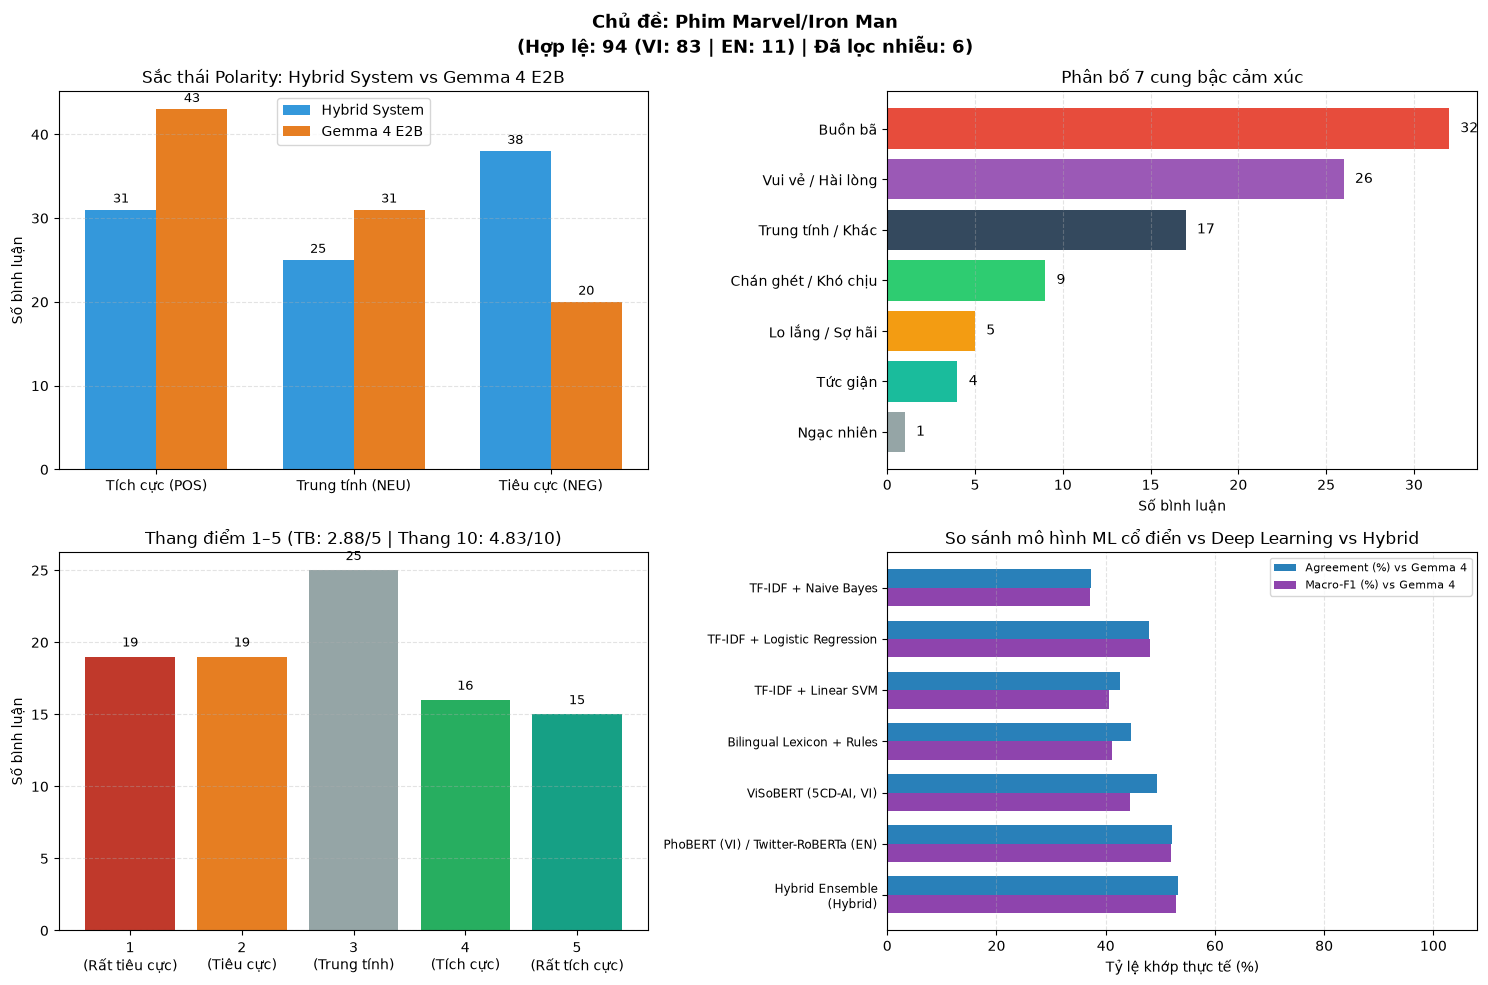

In [5]:
# === DASHBOARD TRỰC QUAN HÓA ===
exported = report.get("exported_files", {})
chart_path = exported.get("dashboard_png") or (OUTPUT_DIR / report["run_name"] / "dashboard.png")
fig = plot_sentiment_dashboard(report, save_path=chart_path)
plt.show()